In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate
from numba import njit,prange
import time
import colormaps as cmaps

import seaborn as sns

import scipy.stats as stats

In [2]:
#### use if you have the stylefile. comment otherwise
plt.style.use("../../style2.mplstyle")

In [3]:
combined_stats = np.load("model_results/combined_stats.npy")

In [4]:
plt.rcParams.update({
    'axes.linewidth': 2
})

## Hill Diversity Change

In [5]:
def plot_boxplot(combined_stats,fig,ax,ylabel,index=2,logflag=False):
    sw_no_phage = combined_stats[:, 0, index]
    sw_phage = combined_stats[:, 1, index]
    pe_no_phage = combined_stats[:, 2, index]
    pe_phage = combined_stats[:, 3, index]

    if logflag:
        sw_no_phage = np.log10(combined_stats[:, 0, index])
        sw_phage = np.log10(combined_stats[:, 1, index])
        pe_no_phage = np.log10(combined_stats[:, 2, index])
        pe_phage = np.log10(combined_stats[:, 3, index])

        sw_no_phage = sw_no_phage[sw_no_phage > -10]
        sw_phage = sw_phage[sw_phage > -10]
        pe_no_phage = pe_no_phage[pe_no_phage > -10]
        pe_phage = pe_phage[pe_phage > -10]

    data = [sw_no_phage, sw_phage, pe_no_phage, pe_phage]
    labels = ['SW\nno phage', 'SW\nphage', 'PE\nno phage', 'PE\nphage']

    colors = ['#8097a2', '#d75151', '#8097a2', '#d75151']  

    bp = ax.boxplot(data, labels=labels, patch_artist=True, 
                    widths=0.5,
                    medianprops=dict(color='black', linewidth=1.5),
                    whiskerprops=dict(color='gray', linewidth=2),
                    capprops=dict(color='gray', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='gray', 
                                    markersize=4, alpha=0.7, markeredgecolor='none'))

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_edgecolor('#333333')
        patch.set_linewidth(2.)      
        patch.set_alpha(1)            

    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(axis='both', labelsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)

    for i, d in enumerate(data, start=1):
        jitter = np.random.normal(0, 0.04, size=len(d))
        ax.scatter(i + jitter, d, alpha=0.4, s=15, color='black', zorder=3)

    fig.tight_layout()

/var/folders/rp/4969vws91431vgg3v1nxd3bw0000gp/T/ipykernel_24223/1291648842.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True,


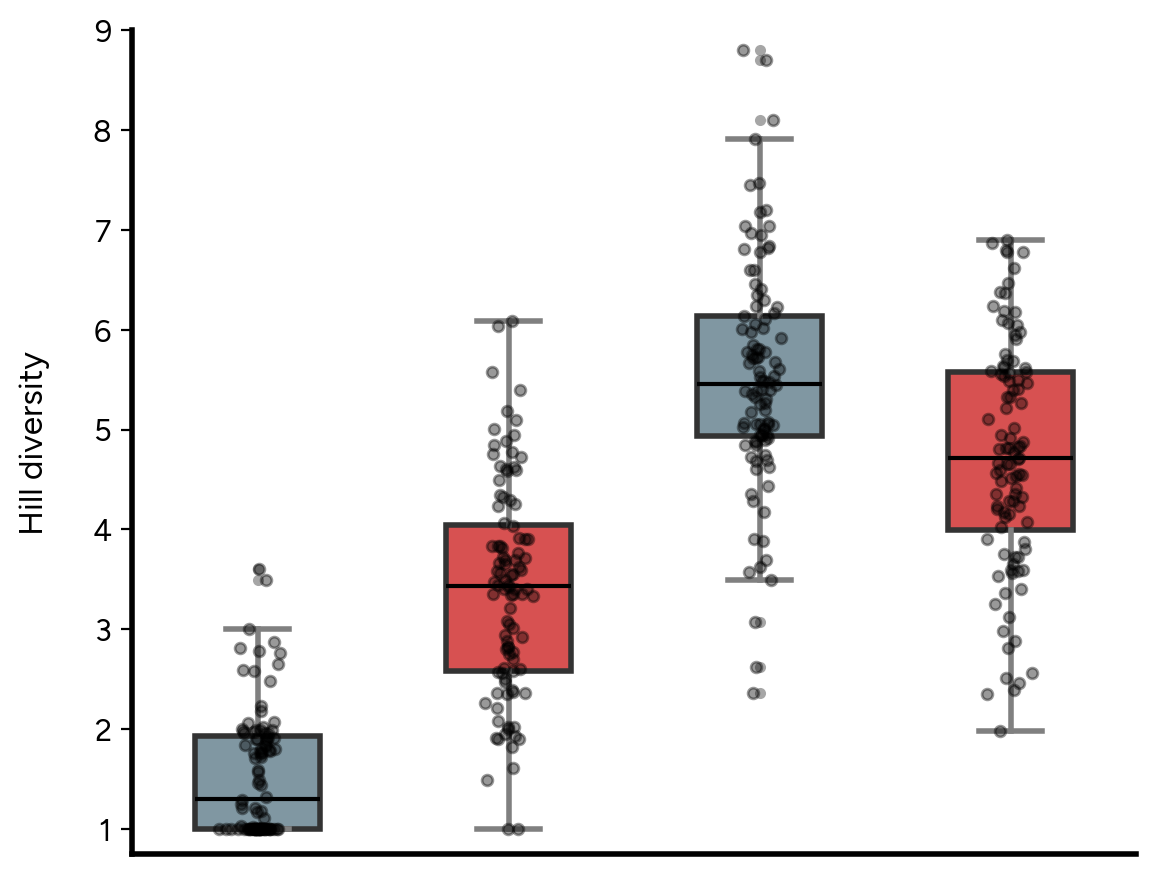

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5),dpi=200)
plot_boxplot(combined_stats,fig,ax,ylabel="Hill diversity",index=2,logflag=False)
ax.set_ylim(0.75,9)
fig.tight_layout()
plt.xticks([],[])
# plt.savefig("figures/hill_diversity_single.svg", dpi=300, bbox_inches='tight')
plt.show()

## Oscillation score

/var/folders/rp/4969vws91431vgg3v1nxd3bw0000gp/T/ipykernel_24223/1291648842.py:8: RuntimeWarning: divide by zero encountered in log10
  sw_no_phage = np.log10(combined_stats[:, 0, index])
/var/folders/rp/4969vws91431vgg3v1nxd3bw0000gp/T/ipykernel_24223/1291648842.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True,


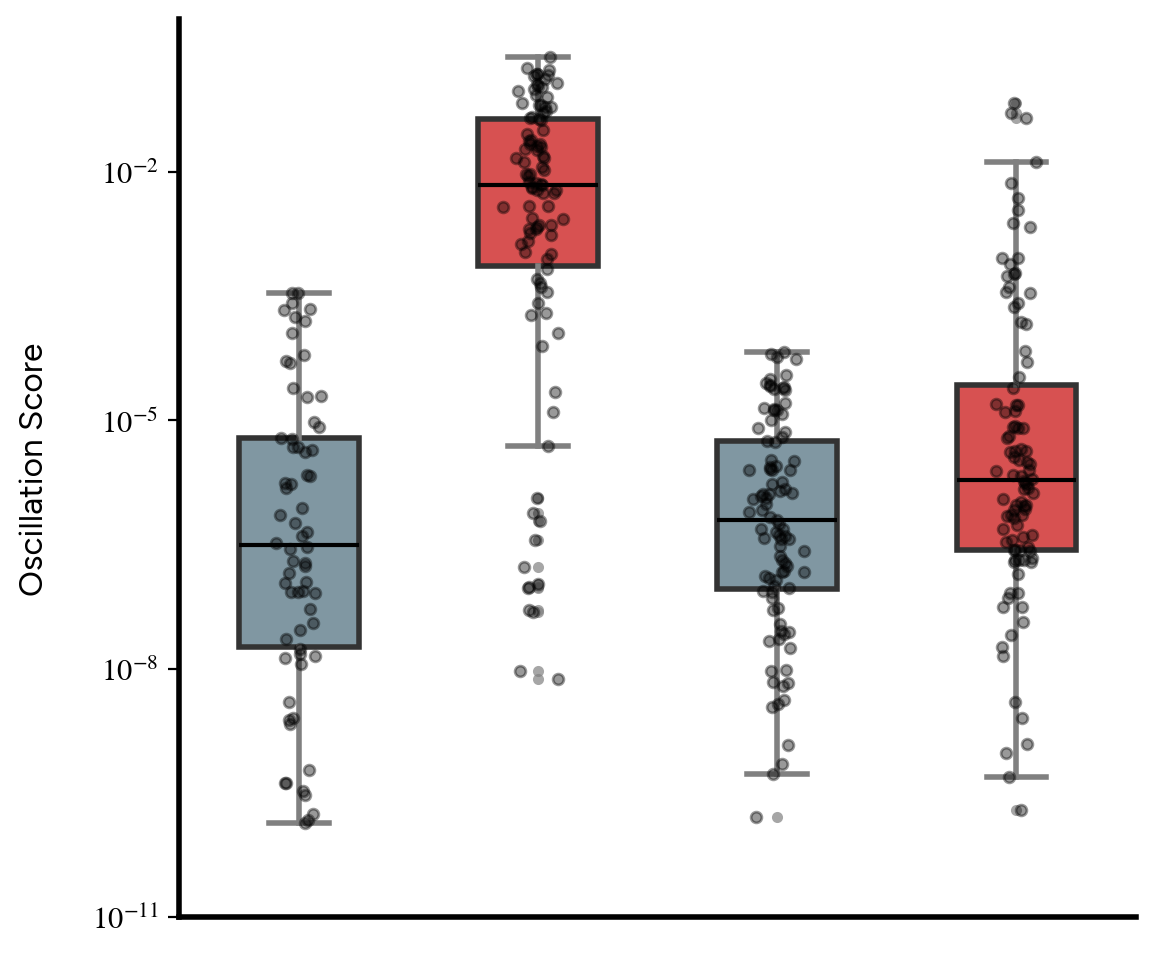

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5),dpi=200)
plot_boxplot(combined_stats,fig,ax,ylabel="Oscillation Score",index=4,logflag=True)
ymin,ymax = plt.ylim()
tickpos = np.arange(np.floor(ymin), 0, 3)
ticklabels = [f"$10^{{{int(y)}}}$" for y in tickpos]
plt.yticks(tickpos, ticklabels)
plt.xticks([],[])

fig.tight_layout()
# plt.savefig("figures/oscillation_single.svg", dpi=300, bbox_inches='tight')
plt.show()

## Correlation

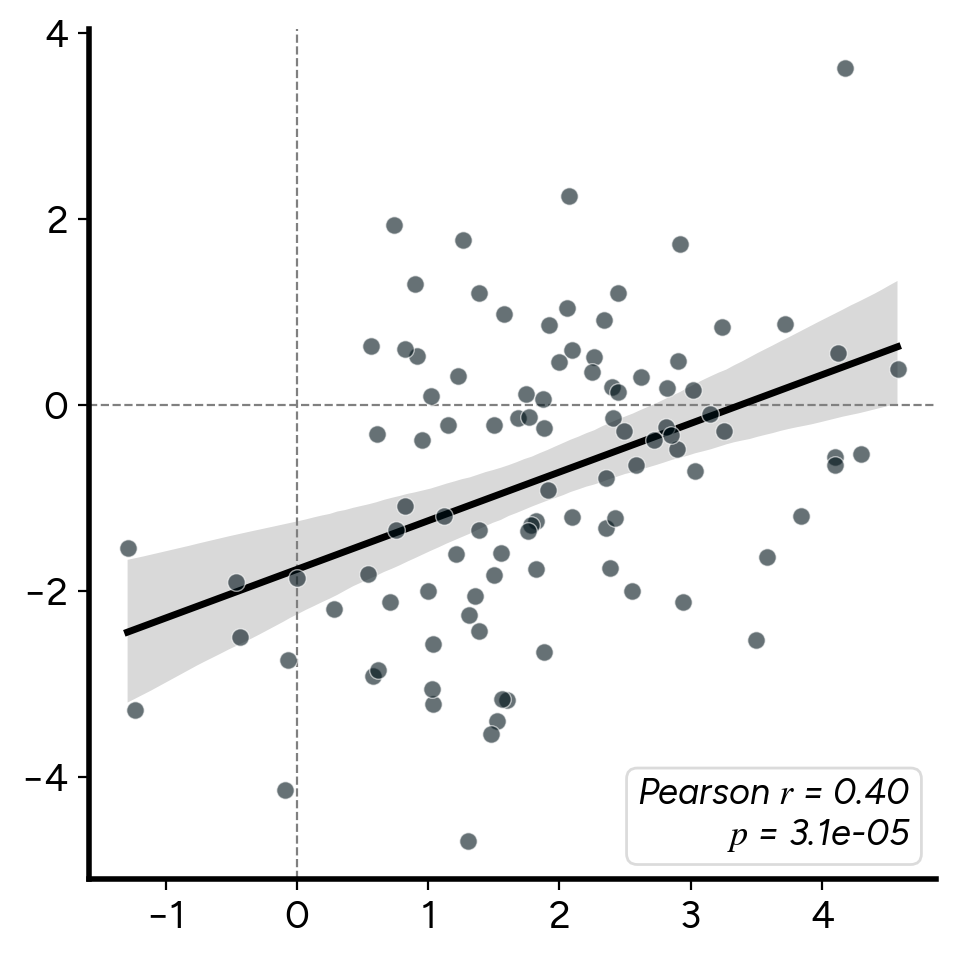

In [ ]:
sw_no_phage = combined_stats[:, 0, 2]
sw_phage = combined_stats[:, 1, 2]
pe_no_phage = combined_stats[:, 2, 2]
pe_phage = combined_stats[:, 3, 2]

delta_sw = sw_phage - sw_no_phage
delta_pe = pe_phage - pe_no_phage

fig, ax = plt.subplots(figsize=(5,5),dpi=200)

corr = stats.pearsonr(delta_sw, delta_pe)

ax.scatter(delta_sw, delta_pe, s=40, alpha=0.6, 
           edgecolors='white', linewidths=0.5, zorder=3)
sns.regplot(x=delta_sw, y=delta_pe, scatter=False, ax=ax,
            line_kws=dict(color='black', linewidth=2.5),
            ci=95)

ax.text(0.97, 0.03, f"Pearson $r$ = {corr[0]:.2f}\n$p$ = {corr[1]:.1e}",
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=13, fontstyle='italic',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                  edgecolor='lightgray', alpha=0.8))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, zorder=1)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8, zorder=1)
fig.tight_layout()
plt.grid(False)
# plt.savefig("figures/correlation_single.svg", dpi=300, bbox_inches='tight')
plt.show()

## Trends across niche overlap

In [27]:
across_shape_data = np.load("model_results/across_shape_stats.npz")
shape_pollen_values = across_shape_data["shape_pollen_values"]
across_shape_stats = across_shape_data["across_shape_stats"]
num_runs = across_shape_stats.shape[1]

delta_pollen_values = np.load("model_results/delta_pollen_values.npz")
delta_pollen_combined = delta_pollen_values['delta_pollen_combined']
expected_niche_overlap_values = delta_pollen_values['expected_niche_overlap_values']

In [28]:
def compute_deltas(cur_stat,index=2):
    pe_no_phage = cur_stat[:, 2, index]
    pe_phage = cur_stat[:, 3, index]
    delta_pe = pe_phage - pe_no_phage
    
    return delta_pe

In [29]:
across_shape_data = np.load("model_results/across_shape_stats.npz")
shape_pollen_values = across_shape_data["shape_pollen_values"]
across_shape_stats = across_shape_data["across_shape_stats"]
num_runs = across_shape_stats.shape[1]

In [30]:
delta_oscillation_score = np.zeros((shape_pollen_values.size, num_runs))
for shape_idx in range(shape_pollen_values.size):
    delta_oscillation_score[shape_idx, :] = compute_deltas(across_shape_stats[shape_idx], index=4)

x_smooth = expected_niche_overlap_values.reshape(-1, 2).mean(axis=1)

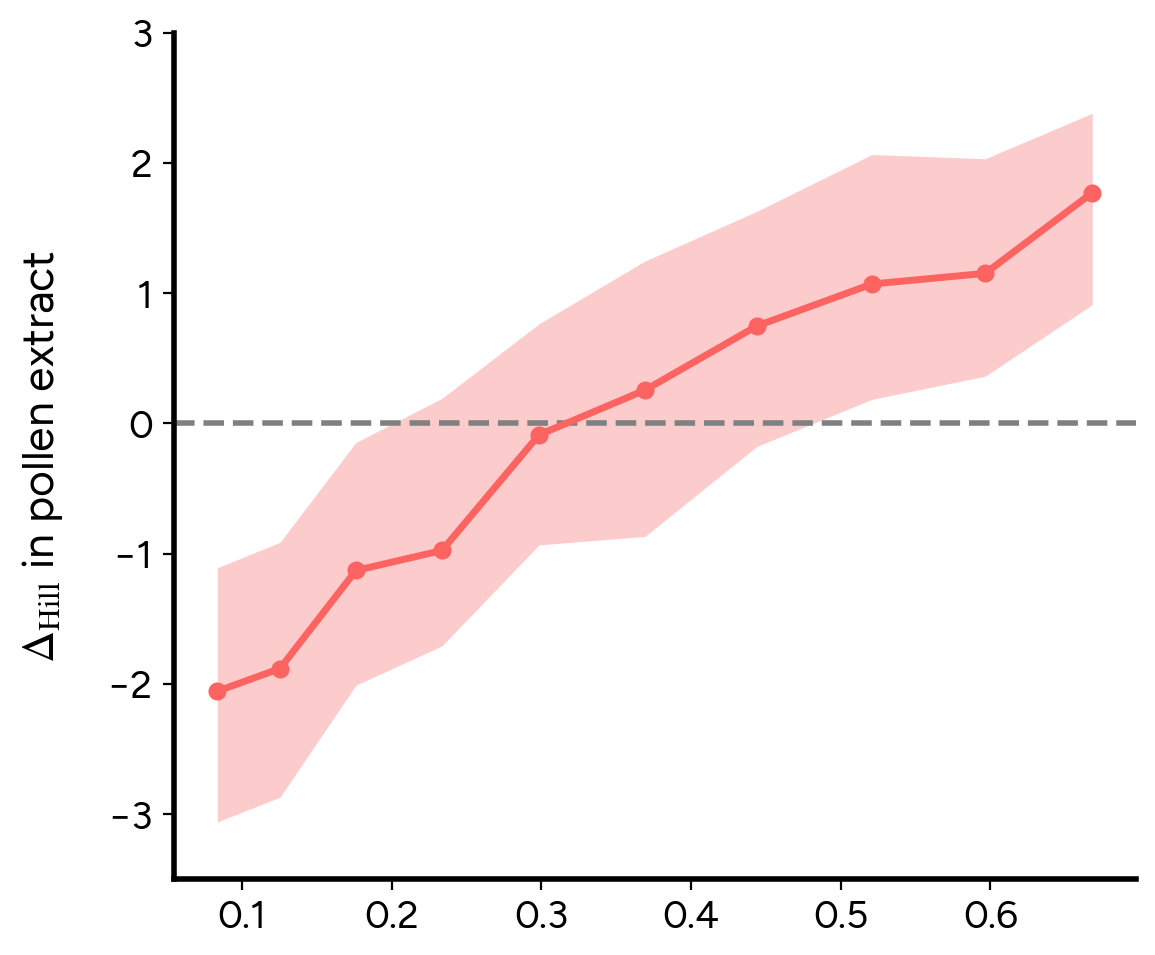

In [34]:
fig, ax = plt.subplots(figsize=(6,5),dpi=200)
median_deltas = np.median(delta_pollen_combined, axis=1)
upper_quantile = np.quantile(delta_pollen_combined, 0.75, axis=1)
lower_quantile = np.quantile(delta_pollen_combined, 0.25, axis=1)

median_smooth = median_deltas.reshape(-1, 2).mean(axis=1)
lower_smooth = lower_quantile.reshape(-1, 2).mean(axis=1)
upper_smooth = upper_quantile.reshape(-1, 2).mean(axis=1)


ax.fill_between(x_smooth, lower_smooth, upper_smooth, 
                alpha=0.4, color="#f7807e", linewidth=0)
ax.plot(x_smooth, median_smooth,'-o', color="#fc6361", linewidth=2.5,markersize=5, markerfacecolor='#fc6361', markeredgewidth=1.5, zorder=3)


ax.axhline(0, color='gray', linestyle='--', linewidth=2, zorder=1)

ax.set_ylabel(r"$\Delta_{\mathrm{Hill}}$ in pollen extract", fontsize=16)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(-3.5,3)
fig.tight_layout()
plt.grid(False)

# plt.savefig("figures/delta_hill_niche.svg", dpi=300, bbox_inches='tight')
plt.show()

/var/folders/rp/4969vws91431vgg3v1nxd3bw0000gp/T/ipykernel_24223/3666458666.py:3: RuntimeWarning: divide by zero encountered in log10
  sugar_no_phage_oscillation = np.log10(across_shape_stats[:,:,0,4])


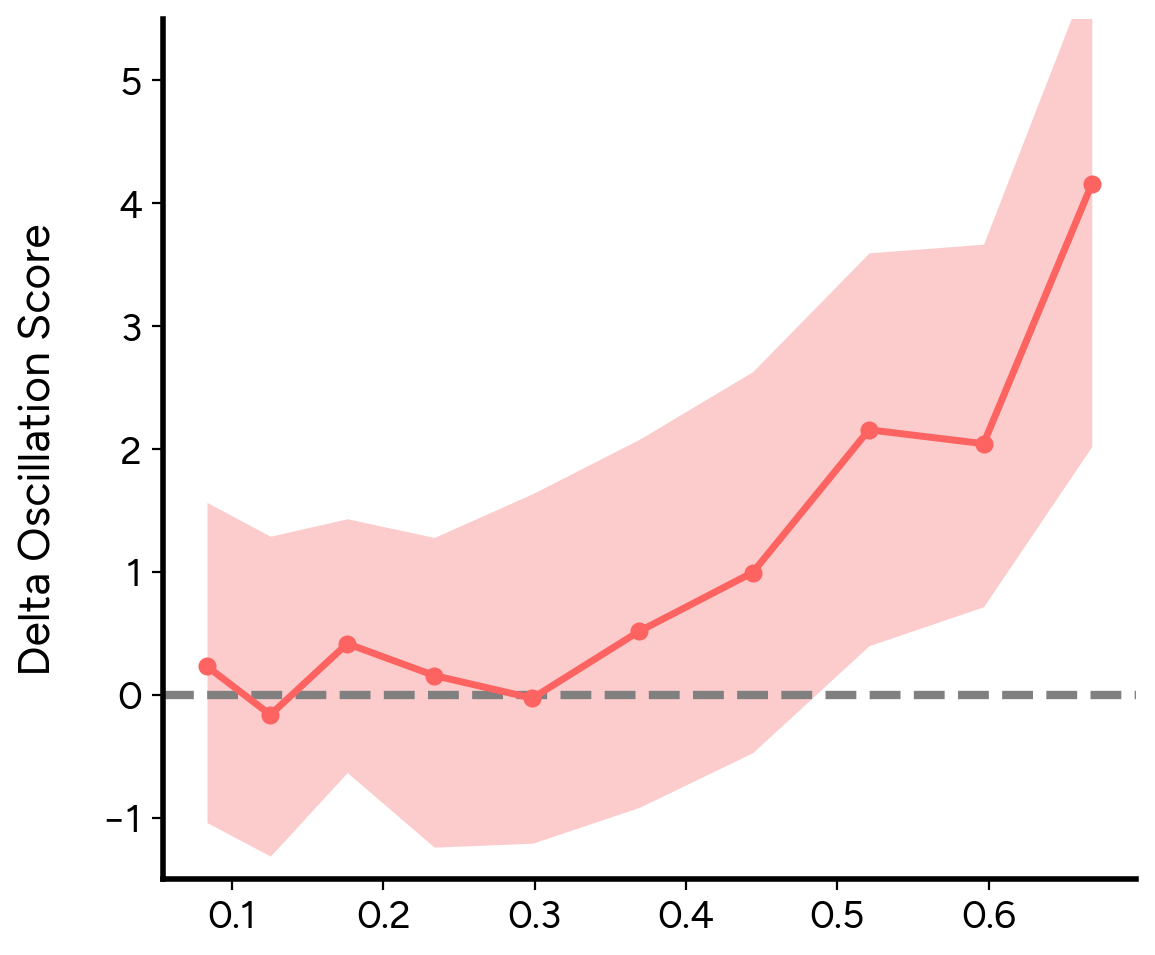

In [36]:
pollen_oscillation = (np.log10(across_shape_stats[:,:,3,4])-np.log10(across_shape_stats[:,:,2,4]))
sugar_oscillation = np.log10(across_shape_stats[:,:,1,4])
sugar_no_phage_oscillation = np.log10(across_shape_stats[:,:,0,4])
median_pollen_oscillation = np.median(pollen_oscillation, axis=1)
upper_quantile_pollen_oscillation = np.quantile(pollen_oscillation, 0.75, axis=1)
lower_quantile_pollen_oscillation = np.quantile(pollen_oscillation, 0.25, axis=1)

oscillation_smooth = median_pollen_oscillation.reshape(-1,2).mean(axis=1)
upper_smooth_oscillation = upper_quantile_pollen_oscillation.reshape(-1,2).mean(axis=1)
lower_smooth_oscillation = lower_quantile_pollen_oscillation.reshape(-1,2).mean(axis=1)

fig, ax = plt.subplots(figsize=(6,5),dpi=200)
ax.fill_between(x_smooth, lower_smooth_oscillation, upper_smooth_oscillation, 
                alpha=0.4, color="#f7807e", linewidth=0)
ax.plot(x_smooth, oscillation_smooth,'-o', color="#fc6361", linewidth=2.5,markersize=5, markerfacecolor='#fc6361', markeredgewidth=1.5, zorder=3,label="Pollen w/ phage")

ax.axhline(0, color="gray", linestyle='--', zorder=2,lw=3)

ax.set_ylabel("Delta Oscillation Score", fontsize=16)
ax.set_ylim(-1.5,5.5)

plt.grid(False)
fig.tight_layout()
plt.savefig("figures/delta_oscillation_niche.svg", dpi=300, bbox_inches='tight')
plt.show()